# Lesson 3. Inner product, other bases and phase

**Goal:** see that measurement can be done in any basis, and understand why the global phase means nothing while the relative phase means a great deal.

## 1. Dictionary: physicists' notation vs linear algebra

The label inside a ket is **the index of a standard basis vector, written in binary**. Basis kets are a *one-hot* encoding: the number in the ket is the position of the 1, counting from zero.

| Dirac notation | Linear algebra |
|---|---|
| $\lvert\psi\rangle$ | column vector $v \in \mathbb{C}^n$ |
| $\langle\psi\rvert$ | $v^{*}$ (conjugate transpose) |
| $\langle\varphi\vert\psi\rangle$ | inner product $\langle u, v\rangle = u^{*}v$ |
| $\lvert\psi\rangle\langle\psi\rvert$ | matrix $v v^{*}$ (projection onto $v$) |
| $\lvert 0\rangle$, $\lvert 1\rangle$ | $e_0 = (1, 0)$, $e_1 = (0, 1)$ |
| $\lvert ab\rangle = \lvert a\rangle \otimes \lvert b\rangle$ | $e_a \otimes e_b = e_{2a+b}$ (Kronecker product) |
| $U\lvert\psi\rangle$ | $Uv$ |

Examples: $|10\rangle$ is $10_2 = 2$, i.e. $e_2 = (0, 0, 1, 0)$; $|101\rangle$ is $e_5 \in \mathbb{C}^8$.

The inner product is linear in the second argument: $\langle u, v\rangle = \sum_k \overline{u_k} v_k$. Conjugation is needed for the norm to be real and non-negative: without it the vector $(1, i)$ would have "length" $1 + i^2 = 0$.

## 2. The Born rule in any basis

For an orthonormal basis $\{u, w\}$:

$$P(u) = |\langle u, v\rangle|^2, \qquad P(w) = |\langle w, v\rangle|^2,$$

and after measurement the state is $u$ or $w$. Measuring in $\{e_0, e_1\}$ is a special case: $\langle e_0, v\rangle = \alpha$.

The most important basis besides the computational one:

$$u_+ = \tfrac{1}{\sqrt{2}}(e_0 + e_1) \;\; (\text{label } |+\rangle), \qquad u_- = \tfrac{1}{\sqrt{2}}(e_0 - e_1) \;\; (\text{label } |-\rangle).$$

Hardware only measures in $\{e_0, e_1\}$. Measuring in another basis is done by rotating the state with a gate before measuring (lesson 5).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
GREEN, DARK, LIGHT, GREY, ORANGE = "#44B749", "#1A8A1F", "#96E199", "#8A8A8A", "#E08A00"

e0 = np.array([1, 0], dtype=complex)   # label |0⟩
e1 = np.array([0, 1], dtype=complex)   # label |1⟩

def norm(v):
    return np.sqrt(np.sum(np.abs(v) ** 2))

def show(v, n=None):
    """Print a state vector with bit labels (label = position written in binary)."""
    v = np.asarray(v)
    n = n or int(np.log2(len(v)))
    for k, a in enumerate(v):
        if abs(a) > 1e-12:
            print(f"  position {k} ({format(k, f'0{n}b')}): amplitude {np.round(a, 3)}, P = {abs(a)**2:.3f}")

up = (e0 + e1) / np.sqrt(2)   # |+⟩
um = (e0 - e1) / np.sqrt(2)   # |-⟩
ip = lambda u, v: np.vdot(u, v)   # inner product <u, v> = u* v

print("<u+, u+> =", round(ip(up, up).real, 3), "  <u-, u-> =", round(ip(um, um).real, 3), "  <u+, u-> =", round(abs(ip(up, um)), 3))

def P_basis(v, basis):
    return [abs(ip(u, v)) ** 2 for u in basis]

for name, v in {"e0": e0, "u+": up, "u-": um}.items():
    print(f"{name}:  z basis: P = {np.round(P_basis(v, [e0, e1]), 3)}   x basis: P = {np.round(P_basis(v, [up, um]), 3)}")

<u+, u+> = 1.0   <u-, u-> = 1.0   <u+, u-> = 0.0
e0:  z basis: P = [1. 0.]   x basis: P = [0.5 0.5]
u+:  z basis: P = [0.5 0.5]   x basis: P = [1. 0.]
u-:  z basis: P = [0.5 0.5]   x basis: P = [0. 1.]

## 3. The global phase does not matter

For any basis and any $\gamma$:

$$|\langle u, e^{i\gamma} v\rangle|^2 = |e^{i\gamma}|^2\, |\langle u, v\rangle|^2 = |\langle u, v\rangle|^2.$$

No measurement in any basis can tell $v$ from $e^{i\gamma} v$. This simply follows from $|e^{i\gamma}| = 1$. For example $e_0$ and $-e_0$ are the same state.

## 4. The relative phase

Write the amplitudes in polar form: $\alpha = |\alpha| e^{i\varphi_\alpha}$, $\beta = |\beta| e^{i\varphi_\beta}$. Then

$$v = e^{i\varphi_\alpha}\big(|\alpha|\, e_0 + |\beta|\, e^{i(\varphi_\beta - \varphi_\alpha)}\, e_1\big).$$

The factor in front is the global phase, which we drop. What remains is

$$\varphi = \varphi_\beta - \varphi_\alpha,$$

the **relative phase**: the angle between the complex numbers $\alpha$ and $\beta$ in the complex plane.

> **This was tricky:** the relative phase does not describe how the basis vectors relate (those are always orthogonal). It describes how the **coordinates** of the state relate. Between the part along $e_0$ and the part along $e_1$ there are two relations: **how much** of each (the ratio $|\alpha| : |\beta|$) and **how far they are shifted in phase** ($\varphi$). Like the coordinates themselves, the relative phase depends on the chosen basis.

Examples (all with $|\alpha| = |\beta| = 1/\sqrt{2}$): $\varphi = 0$ gives $u_+$, $\varphi = \pi$ gives $u_-$, $\varphi = \pi/2$ gives $(e_0 + i e_1)/\sqrt{2}$ (label $|{+i}\rangle$).

## 5. Where the cosine comes from: step by step

Measurement in the basis $\{u_+, u_-\}$:

1. $u_+^{*} = \tfrac{1}{\sqrt{2}}(1, 1)$ (real coefficients, conjugation changes nothing).
2. $\langle u_+, v\rangle = \tfrac{1}{\sqrt{2}}(\alpha + \beta)$.
3. $P(+) = \tfrac{1}{2}|\alpha + \beta|^2$.
4. $|\alpha + \beta|^2 = (\alpha + \beta)(\bar\alpha + \bar\beta) = |\alpha|^2 + |\beta|^2 + \alpha\bar\beta + \bar\alpha\beta$.
5. $\alpha\bar\beta + \bar\alpha\beta = 2\,\mathrm{Re}(\bar\alpha\beta)$, since it is a number plus its conjugate.
6. $\bar\alpha\beta = |\alpha||\beta|\, e^{i(\varphi_\beta - \varphi_\alpha)} = |\alpha||\beta|\, e^{i\varphi}$: conjugation "subtracts" the phase of $\alpha$, leaving the phase difference.
7. $\mathrm{Re}(e^{i\varphi}) = \cos\varphi$ (Euler's formula).
8. Together:

$$P(+) = \tfrac{1}{2}\big(1 + 2|\alpha||\beta|\cos\varphi\big).$$

This is the **law of cosines** for the sum of two plane vectors of lengths $|\alpha|, |\beta|$ at angle $\varphi$. The term $2|\alpha||\beta|\cos\varphi$ is **interference**: it appears only when amplitudes are added **before** taking the modulus. A measurement in $\{e_0, e_1\}$ takes the modulus of each amplitude separately, so it cannot see the relative phase.

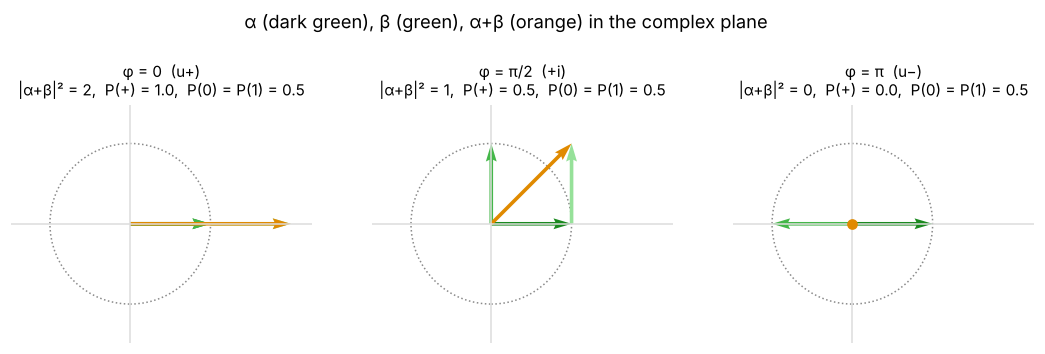

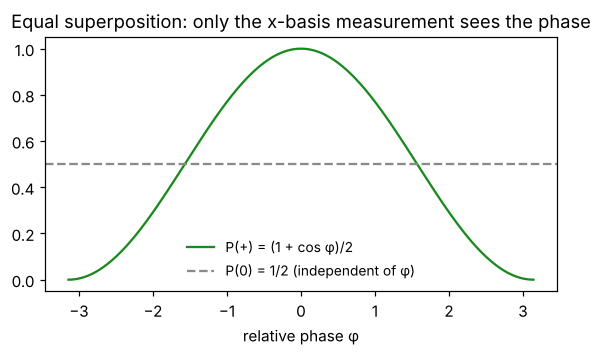

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
a = 1 / np.sqrt(2)
for ax, phi, title in zip(axs, [0, np.pi / 2, np.pi], ["φ = 0  (u+)", "φ = π/2  (+i)", "φ = π  (u−)"]):
    b = a * np.exp(1j * phi); s = a + b
    ax.add_patch(plt.Circle((0, 0), a, fill=False, ls=":", color=GREY))
    ax.axhline(0, color="#DDD", lw=1); ax.axvline(0, color="#DDD", lw=1)
    kw = dict(angles="xy", scale_units="xy", scale=1, width=0.012)
    ax.quiver(0, 0, a, 0, color=DARK, **kw)
    ax.quiver(0, 0, b.real, b.imag, color=GREEN, **kw)
    if abs(s) > 1e-9:
        ax.quiver(a, 0, b.real, b.imag, color=LIGHT, **kw)
        ax.quiver(0, 0, s.real, s.imag, color=ORANGE, **kw)
    else:
        ax.plot(0, 0, "o", color=ORANGE)
    ax.set_title(f"{title}\n|α+β|² = {abs(s)**2:.0f},  P(+) = {abs(s)**2/2:.1f},  P(0) = P(1) = 0.5", fontsize=10)
    ax.set_xlim(-1.05, 1.6); ax.set_ylim(-1.05, 1.05); ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("α (dark green), β (green), α+β (orange) in the complex plane")

phi = np.linspace(-np.pi, np.pi, 300)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(phi, (1 + np.cos(phi)) / 2, color=DARK, label="P(+) = (1 + cos φ)/2")
ax.axhline(0.5, color=GREY, ls="--", label="P(0) = 1/2 (independent of φ)")
ax.set_xlabel("relative phase φ"); ax.legend(frameon=False, fontsize=9)
ax.set_title("Equal superposition: only the x-basis measurement sees the phase")

## 6. A superposition is not a "hidden 0 or 1"

Compare two cases:

- **A:** the system is in the state $u_+$;
- **B:** a "classical coin": the system is really in $e_0$ or in $e_1$, each with probability 1/2, we just do not know which.

In the basis $\{e_0, e_1\}$ both give 50/50. In the basis $\{u_+, u_-\}$:

- A gives "+" 100% of the time, because $u_+$ is a vector of that basis;
- B gives "+" 50% of the time, because $|\langle u_+, e_0\rangle|^2 = |\langle u_+, e_1\rangle|^2 = 1/2$.

This can be measured, and experiments see A. A superposition is a different state from any mixture of zeros and ones.

In [3]:
N = 10_000
rng = np.random.default_rng(1)

# A: always the same state u+
outcomes_A = rng.choice(["+", "-"], size=N, p=P_basis(up, [up, um]))

# B: e0 or e1 at random ("classical coin"), then a measurement in the x basis
states_B = rng.choice([0, 1], size=N)
outcomes_B = np.array([rng.choice(["+", "-"], p=P_basis([e0, e1][s], [up, um])) for s in states_B])

for name, w in (("A: u+", outcomes_A), ("B: coin e0/e1", outcomes_B)):
    print(f"{name:>14}: in the x basis, outcome '+' in {np.mean(w == '+'):.1%} of cases")

         A: u+: in the x basis, outcome '+' in 100.0% of cases
 B: coin e0/e1: in the x basis, outcome '+' in 50.1% of cases

## Summary

> A measurement can be done in any orthonormal basis: $P(u) = |\langle u, v\rangle|^2$. The global phase has no meaning at all, because $|e^{i\gamma}| = 1$. The relative phase $\varphi$ is the angle between $\alpha$ and $\beta$ in the complex plane. It does not change $P(0)$ and $P(1)$, but it decides whether amplitudes reinforce or cancel when a measurement adds them: $P(+) = \tfrac12(1 + 2|\alpha||\beta|\cos\varphi)$.

## Exercises

1. Write $e_1$ in the basis $\{u_+, u_-\}$.
2. State $(3/5, 4/5)$. Compute $P(+)$ and $P(-)$.
3. Can the states $(e_0 + i e_1)/\sqrt{2}$ and $(e_0 - i e_1)/\sqrt{2}$ be told apart by measuring in $\{e_0, e_1\}$? In $\{u_+, u_-\}$? (Hint: for $\varphi = \pm\pi/2$ the formula gives the same $P(+)$. The puzzle is solved in lesson 4.)
4. The state $u_+$ has coordinates $(1/\sqrt2, 1/\sqrt2)$ in the basis $\{e_0, e_1\}$. What are its coordinates in $\{u_+, u_-\}$? What does this say about "being in a superposition"?